# Data Visualization

**Seong Cho** · ACME Python Essentials, Lab 8

**Lab objective:** demonstrate how to communicate information through clean, concise, and honest data visualization.

<sub>Lab specification from the *Python Essentials* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
from scipy.stats import linregress,pearsonr
from scipy.special import binom
from matplotlib import rcParams, colors, pyplot as plt
from itertools import combinations

%matplotlib inline

rcParams["figure.figsize"] = (8,8)

## The Importance of Visualizations

Visualizations of data can reveal insights that are not immediately obvious from simple statistics. The data set in Problem 1, *Anscombe's quartet*, is famous for demonstrating this. (The lab recommends completing the exercises in a Jupyter Notebook.)

## Problem 1: Anscombe's quartet

> **Problem 1.** The file `anscombe.npy` contains the quartet of data points shown in the table below. For each section of the quartet,
> - Plot the data as a scatter plot on the box $[0, 20] \times [0, 13]$.
> - Use `scipy.stats.linregress()` to calculate the slope and intercept of the least squares regression line for the data and its correlation coefficient (the first three return values).
> - Plot the least squares regression line over the scatter plot on the domain $x \in [0, 20]$.
> - Report the mean and variance in $x$ and $y$, the slope and intercept of the regression line, and the correlation coefficient. Compare these statistics to those of the other sections.
> - Describe how the section is similar to the others and how it is different.
>
> | I *x* | I *y* | II *x* | II *y* | III *x* | III *y* | IV *x* | IV *y* |
> |---|---|---|---|---|---|---|---|
> | 10.0 | 8.04 | 10.0 | 9.14 | 10.0 | 7.46 | 8.0 | 6.58 |
> | 8.0 | 6.95 | 8.0 | 8.14 | 8.0 | 6.77 | 8.0 | 5.76 |
> | 13.0 | 7.58 | 13.0 | 8.74 | 13.0 | 12.74 | 8.0 | 7.71 |
> | 9.0 | 8.81 | 9.0 | 8.77 | 9.0 | 7.11 | 8.0 | 8.84 |
> | 11.0 | 8.33 | 11.0 | 9.26 | 11.0 | 7.81 | 8.0 | 8.47 |
> | 14.0 | 9.96 | 14.0 | 8.10 | 14.0 | 8.84 | 8.0 | 7.04 |
> | 6.0 | 7.24 | 6.0 | 6.13 | 6.0 | 6.08 | 8.0 | 5.25 |
> | 4.0 | 4.26 | 4.0 | 3.10 | 4.0 | 5.39 | 19.0 | 12.50 |
> | 12.0 | 10.84 | 12.0 | 9.13 | 12.0 | 8.15 | 8.0 | 5.56 |
> | 7.0 | 4.82 | 7.0 | 7.26 | 7.0 | 6.42 | 8.0 | 7.91 |
> | 5.0 | 5.68 | 5.0 | 4.74 | 5.0 | 5.73 | 8.0 | 6.89 |

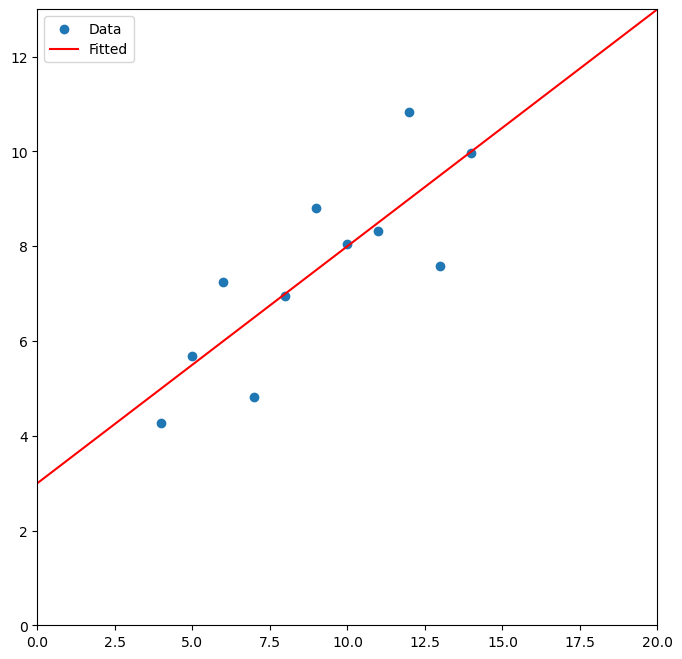

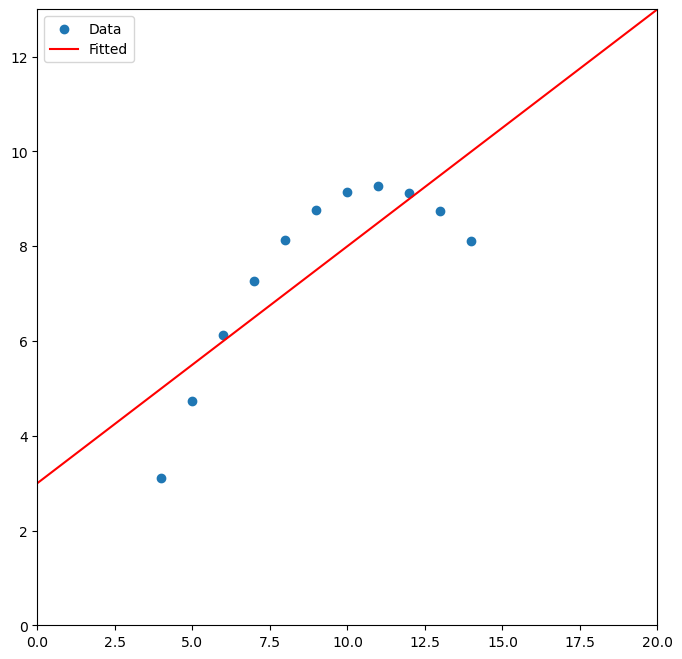

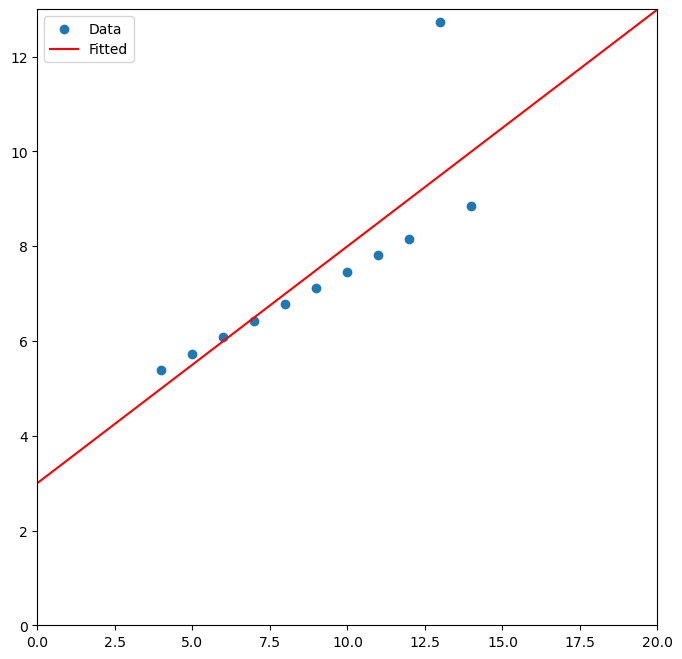

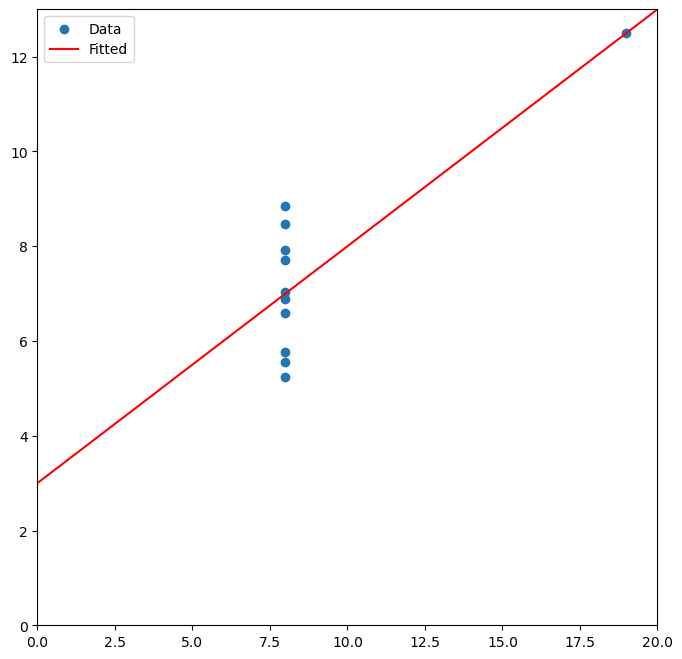

In [2]:
# Problem 1

A = np.load("anscombe.npy")
x = np.linspace(0, 20, 400)

L1 = linregress(A[:,0], A[:,1])
plt.scatter(A[:,0], A[:,1], label="Data")
plt.plot(x, L1[0]*x + L1[1], 'r', label="Fitted")
plt.xlim(0, 20)
plt.ylim(0, 13)
plt.legend()
plt.show()

L2 = linregress(A[:,2], A[:,3])
plt.scatter(A[:,2], A[:,3], label="Data")
plt.plot(x, L2[0]*x + L2[1], 'r', label="Fitted")
plt.xlim(0, 20)
plt.ylim(0, 13)
plt.legend()
plt.show()

L3 = linregress(A[:,4], A[:,5])
plt.scatter(A[:,4], A[:,5], label="Data")
plt.plot(x, L3[0]*x + L3[1], 'r', label="Fitted")
plt.xlim(0, 20)
plt.ylim(0, 13)
plt.legend()
plt.show()

L4 = linregress(A[:,6], A[:,7])
plt.scatter(A[:,6], A[:,7], label="Data")
plt.plot(x, L4[0]*x + L4[1], 'r', label="Fitted")
plt.xlim(0, 20)
plt.ylim(0, 13)
plt.legend()
plt.show()

In [3]:
for i,L in enumerate([L1,L2,L3,L4]):
    print("Section " + str(i+1) + ":")
    print("x mean: " + str(np.mean(A[:,2*i])))
    print("x variance: " + str(np.var(A[:,2*i])))
    print("y mean: " + str(np.mean(A[:,2*i+1])))
    print("y variance: " + str(np.var(A[:,2*i+1]))) 
    print("slope: " + str(L[0]))
    print("intercept: " + str(L[1]))
    print("correlation coefficient: " + str(L[2]))
    print("\n")

Section 1:
x mean: 9.0
x variance: 10.0
y mean: 7.500909090909093
y variance: 3.7520628099173554
slope: 0.5000909090909091
intercept: 3.0000909090909103
correlation coefficient: 0.8164205163448399


Section 2:
x mean: 9.0
x variance: 10.0
y mean: 7.50090909090909
y variance: 3.752390082644628
slope: 0.5000000000000001
intercept: 3.000909090909089
correlation coefficient: 0.816236506000243


Section 3:
x mean: 9.0
x variance: 10.0
y mean: 7.5
y variance: 3.747836363636364
slope: 0.4997272727272729
intercept: 3.002454545454544
correlation coefficient: 0.8162867394895984


Section 4:
x mean: 9.0
x variance: 10.0
y mean: 7.500909090909091
y variance: 3.7484082644628103
slope: 0.4999090909090909
intercept: 3.0017272727272726
correlation coefficient: 0.8165214368885028




Surprisingly, the mean, variance, slope, intercept, and correlation coefficient for each of the sections were exactly the same (or extremely close). It seems that each of these datas were picked so that they would regress to the exact same line. However, It is evident that each of them shows a very different characteristics, and if we were to fit them with a more suitable function, it would help to bring out their characteristics better. 

The first section resembles the result obtained from a real world sampling of a data that could be linear.
The second section seems to be data points of an already continuous quadratic function. 
The third section would be much more accurate if we were allowed to leave out outliers. It would then fit perfectly into the rest of the points.
The last section is similar to the third section. If we left out the outlier, we could fit it with x = 8 which would be a perfect fit.

## Improving Specific Types of Visualizations

Effective visualizations show specific comparisons and relationships. Before designing one, decide what to look for or what needs to be communicated, then choose the visual scheme that makes sense for the data.

### Line plots

A line plot connects ordered $(x, y)$ points with straight lines; it is best for one or two ordered arrays, such as function outputs over an ordered domain or a sequence of values over time. Plotting several lines on top of each other gets hard to read, even with a legend. The example draws the first nine *Chebyshev polynomials*, a family of orthogonal polynomials defined recursively by

$$T_0(x) = 1, \qquad T_1(x) = x, \qquad T_{n+1} = 2xT_n(x) - T_{n-1}(x),$$

first in one plot, then as **small multiples**: a separate titled subplot per polynomial instead of a legend, which makes it easy to compare them and see how each changes as $n$ increases. Adjusting the figure size and line thickness also helps.

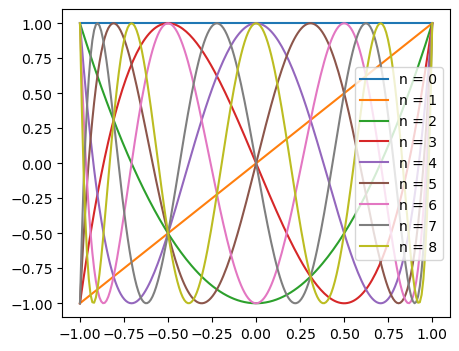

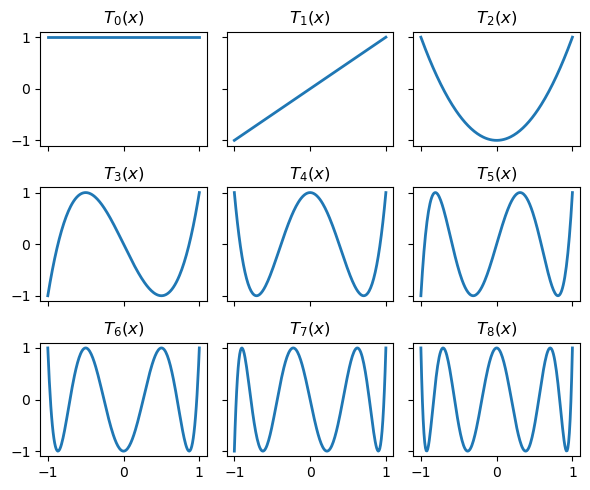

In [4]:
T = np.polynomial.Chebyshev.basis
x = np.linspace(-1, 1, 200)

plt.figure(figsize=(5, 4))
for n in range(9):
    plt.plot(x, T(n)(x), label="n = "+str(n))
plt.axis([-1.1, 1.1, -1.1, 1.1])        # Set the window limits.
plt.legend(loc="right")
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(6, 5), sharex=True, sharey=True)
for n, ax in enumerate(axes.flat):
    ax.plot(x, T(n)(x), lw=2)
    ax.set_title(r"$T_{}(x)$".format(n))
fig.tight_layout()
plt.show()

> **Note.** Matplotlib titles and annotations can be formatted with LaTeX, a system for creating technical documents (see http://www.latex-project.org/). Put an `r` before the string's opening quotation mark and surround the text with dollar signs, as in `plt.title(r"$T_{}(x)$".format(n))` above; `format()` inserts `n` at the curly braces.

## Problem 2: Bernstein basis polynomials

> **Problem 2.** The $n + 1$ Bernstein basis polynomials of degree $n$ are defined as follows:
>
> $$b_{v,n}(x) = \binom{n}{v} x^v (1 - x)^{n-v}, \quad v = 0, 1, \ldots, n$$
>
> Plot the first 10 Bernstein basis polynomials ($n = 0, 1, 2, 3$) as small multiples on the domain $[0, 1] \times [0, 1]$. Label the subplots for clarity, adjust tick marks and labels for simplicity, and set the window limits of each plot to be the same. Consider arranging the subplots so that the rows correspond with $n$ and the columns with $v$.
>
> Hint: The constant $\binom{n}{v} = \frac{n!}{v!(n-v)!}$ is called the *binomial coefficient* and can be efficiently computed with `scipy.special.binom()` or `scipy.misc.comb()`.

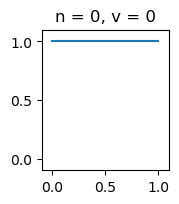

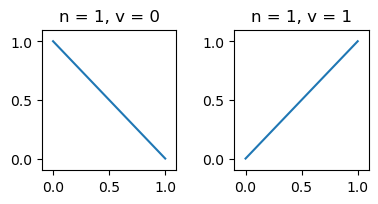

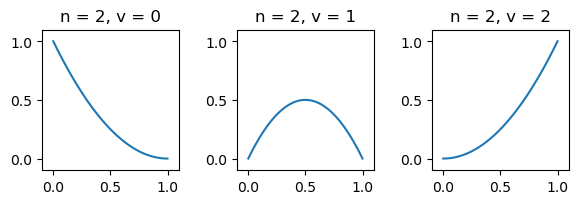

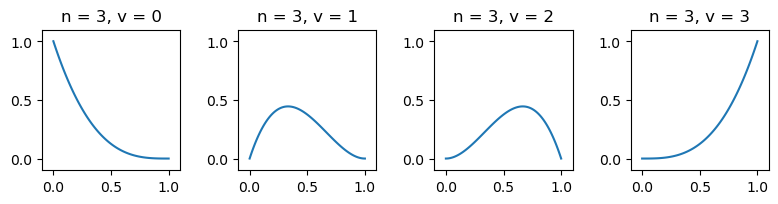

In [5]:
# Problem 2

x = np.linspace(0,1,100)
def berstein(n, v):
    return lambda x: binom(n,v)*(x**v)*(1-x)**(n-v)

for n in [0,1,2,3]:
    fig, ax = plt.subplots(1,n+1, figsize=(2*(n+1),2))
    fig.tight_layout()
    for v in range(n+1):
        b = berstein(n,v)
        if n != 0:
            ax[v].plot(x, b(x))
            ax[v].axis([-0.1, 1.1, -0.1, 1.1])
            ax[v].yaxis.set_ticks([0.0,0.5,1.0])
            ax[v].set_title("n = " + str(n) + ", v = " + str(v))
        else:
            ax.plot(x, b(x))
            ax.axis([-0.1, 1.1, -0.1, 1.1]) 
            ax.yaxis.set_ticks([0.0,0.5,1.0])
            ax.set_title("n = " + str(n) + ", v = " + str(v))

    plt.show()

### Bar charts

A bar chart plots categorical data as a sequence of bars; it is best for small, discrete, one-dimensional data sets. `plt.bar()` makes vertical bars and `plt.barh()` horizontal ones, given the bar locations and then the bar heights. Horizontal bar charts are usually preferable, because horizontal labels are easier to read than vertical (or rotated) ones. Sort the data in a logical way, such as alphabetically, by size, or by importance.

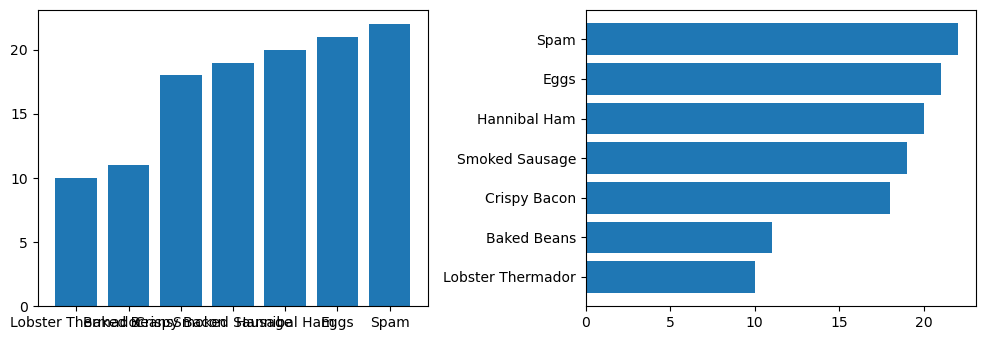

In [6]:
labels = ["Lobster Thermador", "Baked Beans", "Crispy Bacon",
          "Smoked Sausage", "Hannibal Ham", "Eggs", "Spam"]
values = [10, 11, 18, 19, 20, 21, 22]
positions = np.arange(len(labels))

fig = plt.figure(figsize=(10, 3.5))
ax = fig.add_subplot(121)                   # Vertical bar chart.
ax.bar(positions, values, align="center")
ax.set_xticks(positions, labels)
ax = fig.add_subplot(122)                   # Horizontal bar chart (better).
ax.barh(positions, values, align="center")
ax.set_yticks(positions, labels)
fig.tight_layout()
plt.show()

### Histograms

A histogram partitions an interval into bins and counts the values in each, which makes it ideal for showing how unordered data in a single array is distributed; for samples from a probability distribution it approximates the density function. `bins` and `range` give the number of bins and the domain. Experiment with the bin count: too few or too many bins hide the distribution. Here 10 bins say little, while 35 reveal the shape of a normal distribution.

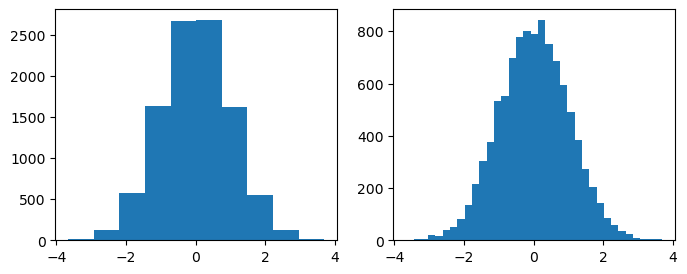

In [7]:
data = np.random.normal(size=10000)
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].hist(data, bins=10)
ax[1].hist(data, bins=35)
plt.show()

### Scatter plots

A scatter plot (`plt.scatter()`) draws $(x, y)$ points without connecting them. It suits data without a natural order, or where each point is a distinct, individual instance, and is often used to show correlation between variables. (`plt.plot()` with a point marker such as `'.'`, `','`, `'o'`, or `'+'` gives an ordered scatter plot; in `plt.scatter()`, the keywords `s` and `c` set marker size and color.)

When markers overlap, `alpha` (from 0, transparent, to 1, opaque) reveals the overlap, and `edgecolor='none'` removes cluttering marker outlines. Below, the default axes (left) hide the pattern, while equal axes (right) reveal the oscillation in the perturbed sine wave.

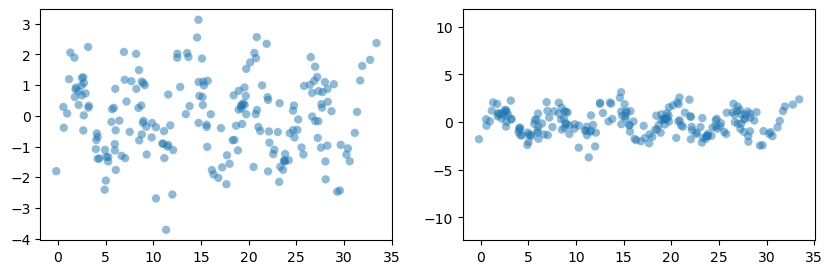

In [8]:
np.random.seed(0)
x = np.linspace(0, 10*np.pi, 200) + np.random.normal(size=200)
y = np.sin(x) + np.random.normal(size=200)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].scatter(x, y, alpha=.5, edgecolor='none')
ax[1].scatter(x, y, alpha=.5, edgecolor='none')
ax[1].axis('equal')
plt.show()

## Problem 3: MLB heights, weights, and ages

> **Problem 3.** The file `MLB.npy` contains measurements from over 1,000 recent Major League Baseball players, compiled by UCLA. (See http://wiki.stat.ucla.edu/socr/index.php/SOCR_Data_MLB_HeightsWeights.) Each row in the array represents a player; the columns are the player's height (in inches), weight (in pounds), and age (in years), in that order.
>
> Create several visualizations to show the correlations between height, weight, and age in the MLB data set. Use at least one scatter plot. Adjust the marker size, plot a regression line, change the window limits, and use small multiples where appropriate.

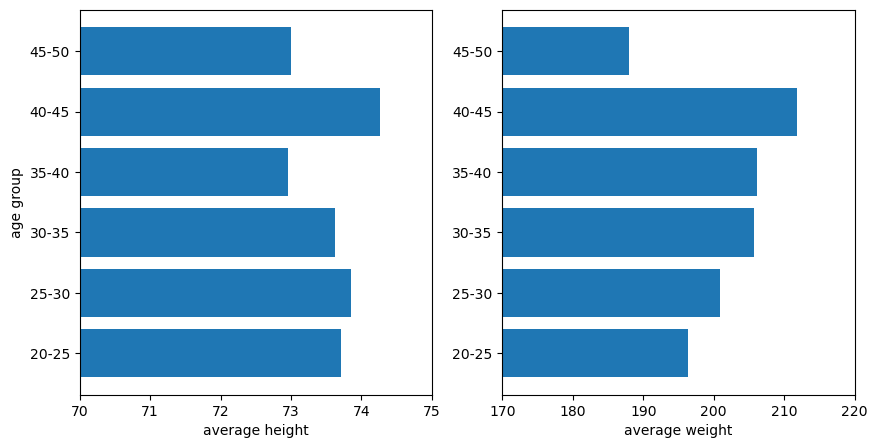

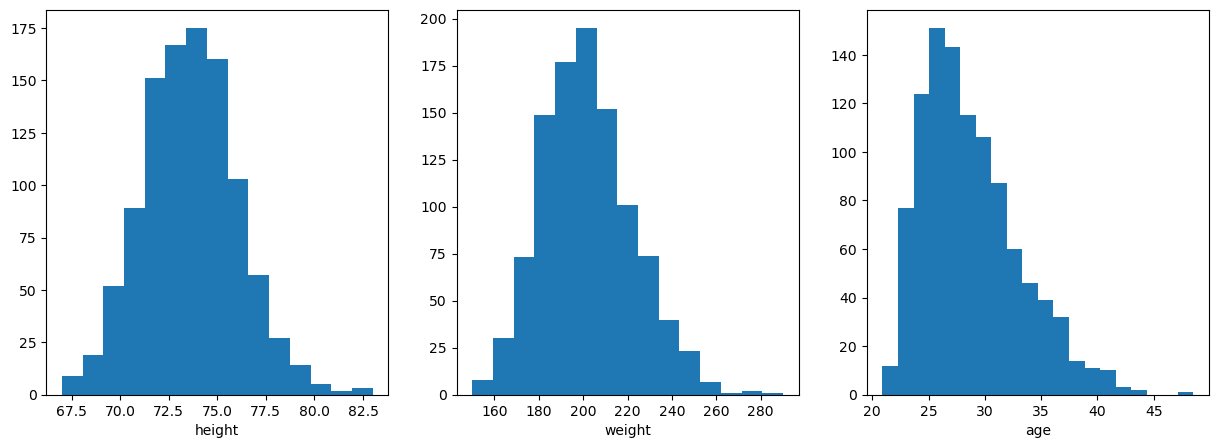

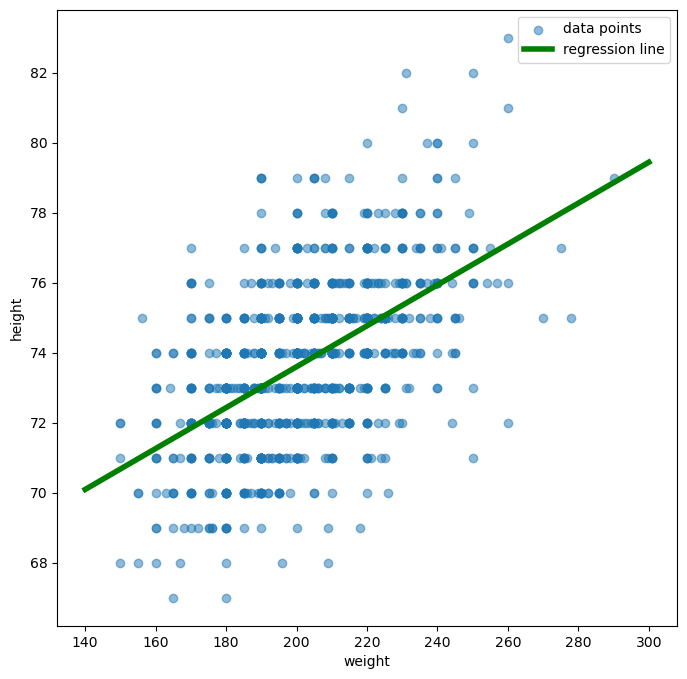

In [9]:
# Problem 3
height, weight, age = np.load("MLB.npy").T

age_group = np.arange(20,50,5)
labels = [str(i) + "-" + str(i+5) for i in age_group]
ave_height = [np.mean(height[np.intersect1d(np.where(age >= i), np.where(age < i+5))]) for i in age_group]
ave_weight = [np.mean(weight[np.intersect1d(np.where(age >= i), np.where(age < i+5))]) for i in age_group]
positions = np.arange(len(labels))

fig1, ax1 = plt.subplots(1,2, figsize=(10, 5))
ax1[0].barh(positions, ave_height, align="center")
ax1[0].set_ylabel("age group")
ax1[0].set_xlabel("average height")
ax1[0].set_yticks(positions)
ax1[0].set_yticklabels(labels)   # Fixed: labels[::-1] put the 45-50 label on the 20-25 bar.
ax1[0].set_xlim(70, 75)

ax1[1].barh(positions, ave_weight, align="center")
ax1[1].set_xlabel("average weight")
ax1[1].set_yticks(positions)
ax1[1].set_yticklabels(labels)   # Fixed: same reversed labels.
ax1[1].set_xlim(170, 220)
plt.show()

fig2, ax2 = plt.subplots(1,3, figsize=(15, 5))
ax2[0].hist(height, bins=15)
ax2[0].set_xlabel("height")
ax2[1].hist(weight, bins=15)
ax2[1].set_xlabel("weight")
ax2[2].hist(age, bins=20)
ax2[2].set_xlabel("age")
plt.show()

L = linregress(weight, height)
x = np.linspace(140, 300, 100)
plt.scatter(weight, height, alpha=.5, label="data points")
plt.plot(x, L[0]*x + L[1], 'g', linewidth=4.0, label="regression line")
plt.ylabel("height")
plt.xlabel("weight")
plt.legend()
plt.show()

## Problem 4: Earthquakes, 2000–2010

> **Problem 4.** The file `earthquakes.npy` contains data from over 17,000 earthquakes between 2000 and 2010 that were at least a 5 on the Richter scale. (See http://earthquake.usgs.gov/earthquakes/search/.) Each row in the array represents an earthquake; the columns are the earthquake's date (as a fraction of the year), magnitude (on the Richter scale), longitude, and latitude, in that order.
>
> Because each earthquake is a distinct event, a good way to start visualizing this data might be a scatter plot of the years versus the magnitudes of each earthquake.
>
> ```python
> year, magnitude, longitude, latitude = np.load("earthquakes.npy").T
> plt.plot(year, magnitude, '.')
> plt.xlabel("Year")
> plt.ylabel("Magnitude")
> ```
>
> Unfortunately, this plot communicates very little information because the data is so cluttered. Describe the data with at least two better visualizations, including line plots, scatter plots, and histograms as appropriate. Your plots should answer the following questions:
> 1. How many earthquakes happened every year?
> 2. How often do stronger earthquakes happen compared to weaker ones?
> 3. Where do earthquakes happen? Where do the strongest earthquakes happen?
>
> (Hint: Use `plt.axis("equal")` or `ax.set_aspect("equal")` to fix the aspect ratio, which may improve comparisons between longitude and latitude.)

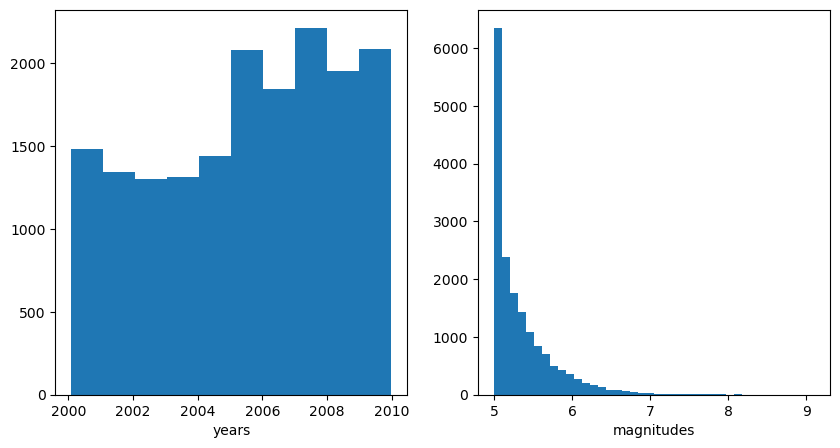

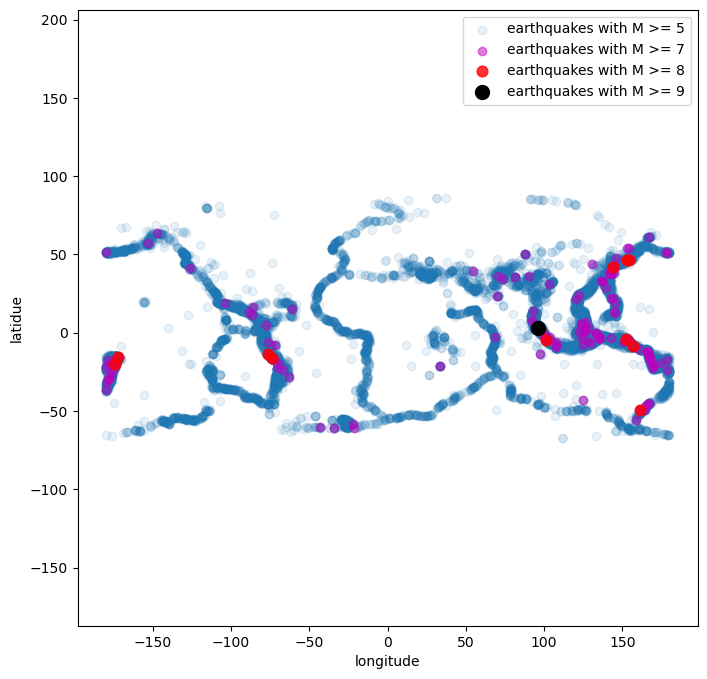

In [10]:
# Problem 4
years, magnitudes, longitude, latitude = np.load("earthquakes.npy").T

fig1, ax1 = plt.subplots(1,2, figsize=(10, 5))
ax1[0].hist(years, bins=10)
ax1[0].set_xlabel("years")
ax1[1].hist(magnitudes, bins=40)
ax1[1].set_xlabel("magnitudes")
plt.show()

plt.scatter(longitude, latitude, alpha=.1, label="earthquakes with M >= 5")
plt.scatter(longitude[np.where(magnitudes>=7)], latitude[np.where(magnitudes>=7)], c='m', alpha=0.5, label="earthquakes with M >= 7")
plt.scatter(longitude[np.where(magnitudes>=8)], latitude[np.where(magnitudes>=8)], c='r', s=60, alpha=0.8, label="earthquakes with M >= 8")
plt.scatter(longitude[np.where(magnitudes>=9)], latitude[np.where(magnitudes>=9)], c='k', s=100, alpha=1.0, label="earthquakes with M >= 9")

plt.axis("equal")
plt.xlabel("longitude")
plt.ylabel("latidue")
plt.legend()
plt.show()

The magnitudes above 8:

In [11]:
magnitudes[np.where(magnitudes>8)]

array([8.1, 8.5, 8.1, 8.1, 8.3, 8.6, 9.1, 8.1, 8.3, 8.4])

> _Answer not written in the original notebook._ (No written answers to questions 1–3; the plots above are the response.)

### Hexbins

A *hexbin* shows the frequency of occurrences in a 2-D plane: like a histogram, it sorts the data into bins (hexagons in a grid) but uses color instead of height for the count, in place of a 3-D histogram. An effective hexbin needs an appropriate `gridsize` and colormap (`cmap`). Below, the same random data with gridsize 10 (left) and 25 (right), both in the `'inferno'` colormap.

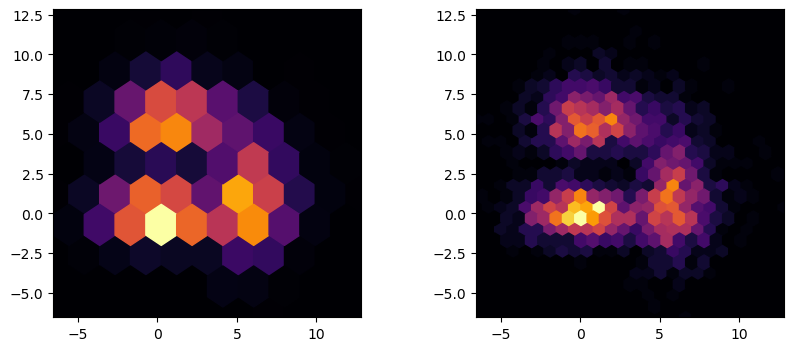

In [12]:
a = np.random.exponential(size=1000) + np.random.normal(size=1000) + 5
b = np.random.exponential(size=1000) + 2*np.random.normal(size=1000)
x = np.hstack((a, b, 2*np.random.normal(size=1000)))
y = np.hstack((b, a, np.random.normal(size=1000)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
window = [x.min(), x.max(), y.min(), y.max()]
for ax, size in zip(axes, [10, 25]):
    ax.hexbin(x, y, gridsize=size, cmap='inferno')
    ax.axis(window)
    ax.set_aspect("equal")
plt.show()

### Heat maps and contour plots

For $f: \mathbb{R}^2 \to \mathbb{R}$, a *heat map* colors each $(x, y)$ by the value of $f(x, y)$, and a *contour plot* draws the *level curves* $\{(x, y) \mid c = f(x, y)\}$. A filled contour plot colors between the level curves and is a discretized heat map. By default the constants $c$ are evenly spaced over the range of $f$, but it is sometimes better to choose them. For $f(x, y) = y^2 - x^3 + x^2$ on $[-\frac{3}{2}, \frac{3}{2}] \times [-\frac{3}{2}, \frac{3}{2}]$, the heat map shows a large basin around the origin; since $f(0, 0) = 0$, level curves near 0 ($c = -1, -\frac{1}{4}, 0, \frac{1}{4}, 1, 4$) describe the basin's topography more closely (bottom right).

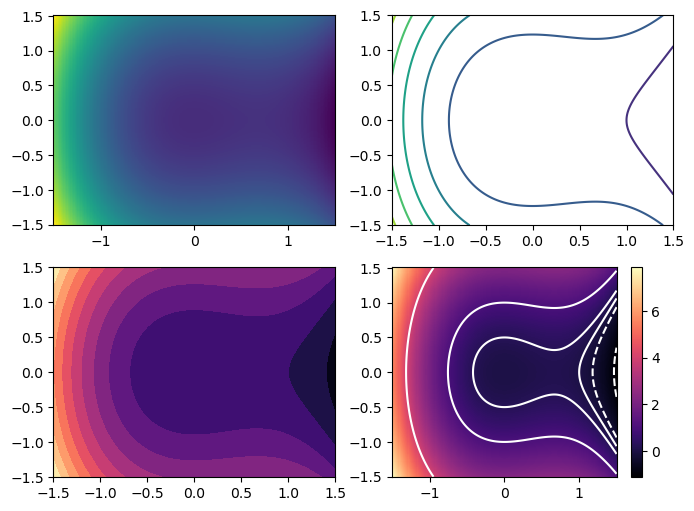

In [13]:
x = np.linspace(-1.5, 1.5, 200)
X, Y = np.meshgrid(x, x)
Z = Y**2 - X**3 + X**2

fig, ax = plt.subplots(2, 2, figsize=(8, 6))
ax[0,0].pcolormesh(X, Y, Z, cmap="viridis")                 # Heat map.
ax[0,1].contour(X, Y, Z, 6, cmap="viridis")                 # Contour map.
ax[1,0].contourf(X, Y, Z, 12, cmap="magma")                 # Filled contour map.
ax[1,1].contour(X, Y, Z, [-1, -.25, 0, .25, 1, 4], colors="white")
cax = ax[1,1].pcolormesh(X, Y, Z, cmap="magma")             # Heat map with level curves.
fig.colorbar(cax, ax=ax[1,1])
plt.show()

Choose a colormap that best represents the data. Avoid spectral or rainbow colormaps like `"jet"`: they are not *perceptually uniform* (the rate of change in color is not constant), so points may look closer together or farther apart than they are, creating visual false positives or negatives. As a default, the lab recommends the sequential colormaps `"viridis"` or `"inferno"`, which are perceptually uniform and colorblind friendly. Full list: http://matplotlib.org/examples/color/colormaps_reference.html.

## Problem 5: The Rosenbrock function

> **Problem 5.** The *Rosenbrock function* is defined as follows.
>
> $$f(x, y) = (1 - x)^2 + 100(y - x^2)^2$$
>
> The minimum value of $f$ is $0$, which occurs at the point $(1, 1)$ at the bottom of a steep, banana-shaped valley of the function.
>
> Use a heat map and a contour plot to visualize the Rosenbrock function. Plot the minimizer $(1, 1)$. Use a different sequential colormap for each visualization.

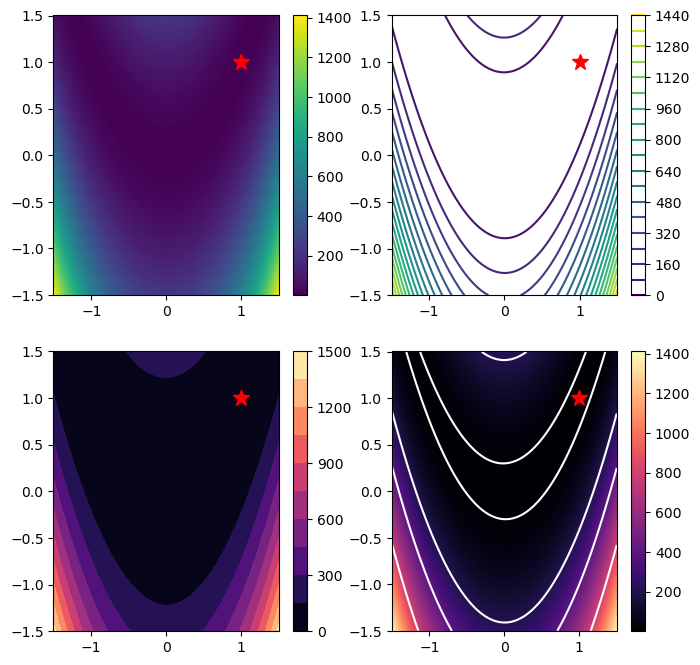

In [14]:
# Problem 5
rosen = lambda x,y: (1. - x)**2 + 100.*(y - x**2)**2

x = np.linspace(-1.5,1.5,300)
X,Y = np.meshgrid(x,x)

fig, ax = plt.subplots(2,2)
ax1=ax[0,0].pcolormesh(X, Y, rosen(X,Y), cmap="viridis")
ax2=ax[0,1].contour(X, Y, rosen(X,Y), 20, cmap="viridis")
ax3=ax[1,0].contourf(X, Y, rosen(X,Y), 12, cmap="magma")
ax4=ax[1,1].contour(X, Y, rosen(X,Y), [0,10,200,400,800], colors="white")
cax = ax[1,1].pcolormesh(X, Y, rosen(X,Y), cmap="magma")
fig.colorbar(ax1, ax=ax[0,0])
fig.colorbar(ax2, ax=ax[0,1])
fig.colorbar(ax3, ax=ax[1,0])
fig.colorbar(cax, ax=ax[1,1])
for a in ax.flat:
    a.plot(1, 1, 'r*', markersize=12)    # Added: the spec asks to plot the minimizer (1, 1).

plt.show()

## Best Practices

Good scientific visualizations make comparison easy and clear. The eye is very good at detecting variation in one dimension and poor in two or more: most people can guess which slice of a pie chart is largest, but not confidently say *by how much*, which a bar chart makes easy. Avoid pie charts and other visualizations that make accurate comparison difficult, such as radar charts, bubble charts, and stacked bar charts.

No visualization perfectly represents data, so finding the best one is iterative: experiment with color, scale, size, shape, position, and length, and transform the data or visualize subsets when needed. Keep in mind the saying attributed to George Box: "All models are wrong, but some are useful."

**Chartjunk** (Edward Tufte's term) is anything — pictures, icons, colors, text — that does not represent data or is distracting. It may make a graphic more memorable, but clarity and precision matter more, to prevent misinterpretation. The lab cites Richard Feynman: "For a successful technology, reality must take precedence over public relations, for Nature cannot be fooled." Remove anything that keeps the viewer from interpreting the data objectively.

Visualizations should be **honest**. The lab's example is a misleading chart shown at a United States congressional hearing in 2015 (abortions vs. cancer screenings and prevention services, 2006–2013, source: Americans United for Life): with the $y$-axis removed, it is easy to miss that each line is on a different $y$-axis though both are in the same units, and the chart doesn't show that data from 2008 is missing (see http://www.politifact.com/truth-o-meter/statements/2015/oct/01/jason-chaffetz/chart-shown-planned-parenthood-hearing-misleading-/).

Never use data visualizations to deceive or manipulate. Always present who created the visualization, where the data came from, how it was collected, whether it was cleaned or transformed, and whether there are conflicts of interest or possible biases. Use specific titles and axis labels, include units of measure, choose an appropriate window size, and use a legend or other annotations where appropriate.

## Problem 6: Twenty countries

> **Problem 6.** The file `countries.npy` contains information from 20 different countries. Each row in the array represents a different country; the columns are the 2015 population (in millions of people), the 2015 GDP (in billions of US dollars), the average male height (in centimeters), and the average female height (in centimeters), in that order. (See https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal), https://en.wikipedia.org/wiki/List_of_countries_and_dependencies_by_population, and http://www.averageheight.co/.)
>
> The countries corresponding are listed below in order.
>
> ```python
> countries = ["Austria", "Bolivia", "Brazil", "China",
>              "Finland", "Germany", "Hungary", "India",
>              "Japan", "North Korea", "Montenegro", "Norway",
>              "Peru", "South Korea", "Sri Lanka", "Switzerland",
>              "Turkey", "United Kingdom", "United States", "Vietnam"]
> ```
>
> Visualize this data set with at least four plots, using at least one scatter plot, one histogram, and one bar chart. List the major insights that your visualizations reveal.
>
> (Hint: consider using `np.argsort()` and fancy indexing to sort the data for the bar chart.)

In [15]:
# Problem 6
countries = np.array(
            ["Austria", "Bolivia", "Brazil", "China", "Finland",
             "Germany", "Hungary", "India", "Japan", "North Korea",
             "Montenegro", "Norway", "Peru", "South Korea", "Sri Lanka",
             "Switzerland", "Turkey", "United Kingdom", "United States", "Vietnam"])
population, gdp, male, female = np.load("countries.npy").T

### Height

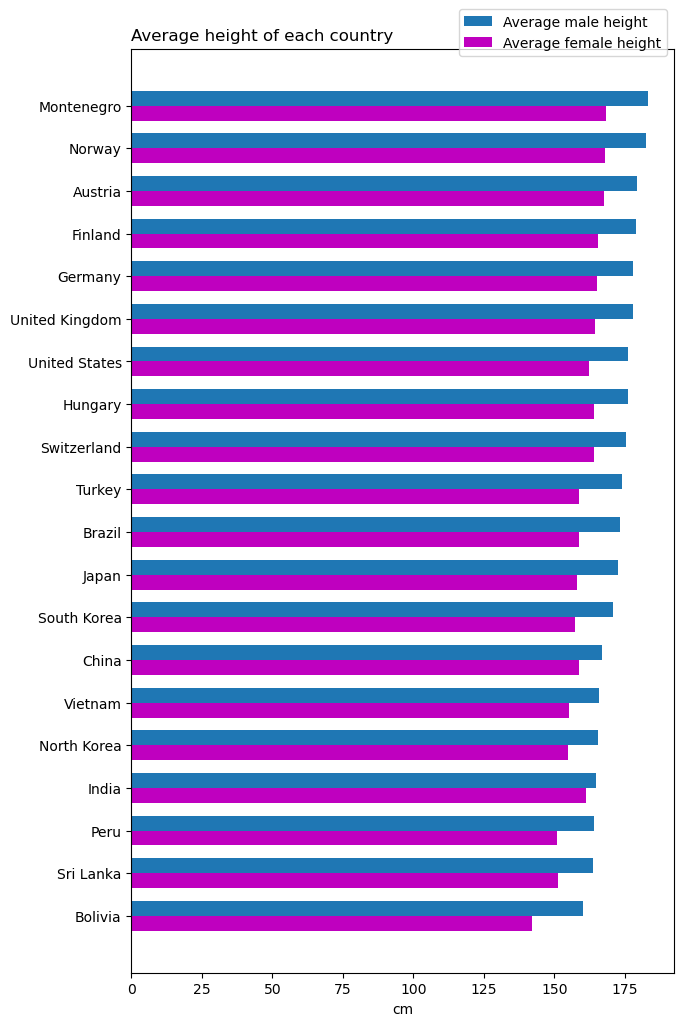

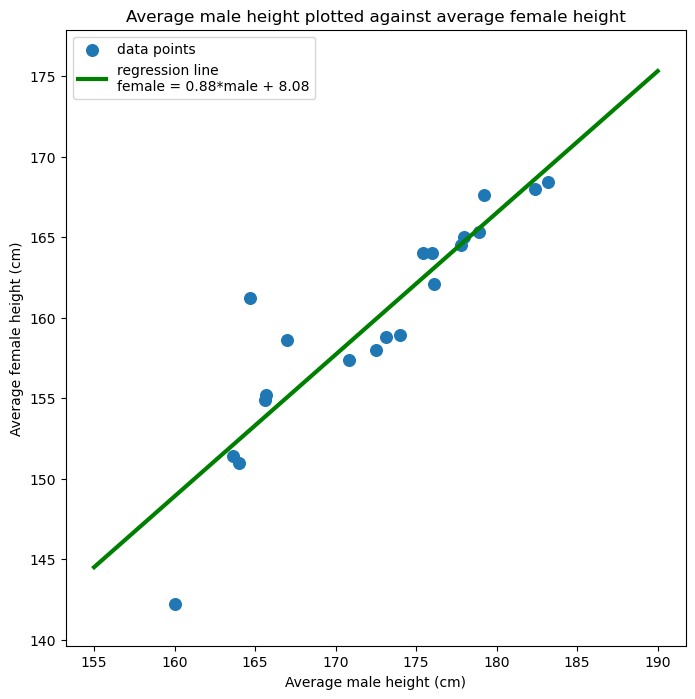

In [16]:
positions = np.arange(len(countries))
width = 0.35

plt.figure(figsize=(7,12))
plt.barh(positions+width/2, np.sort(male), width, label="Average male height")
plt.barh(positions-width/2, female[np.argsort(male)], width, color='m', label="Average female height")
plt.yticks(positions, countries[np.argsort(male)])
plt.xlabel('cm')
plt.legend(bbox_to_anchor=(1.0, 1.05))
plt.title("Average height of each country", loc="left")
plt.show()

L = linregress(male, female)
x = np.linspace(155, 190, 100)
plt.scatter(male, female, s=70, label="data points")
plt.plot(x, L[0]*x + L[1], color='g', linewidth=3, label="regression line \nfemale = " 
                                                         + str(round(L[0],3)) + "*male + " 
                                                         + str(round(L[1],3)))
plt.xlabel("Average male height (cm)")
plt.ylabel("Average female height (cm)")
plt.title("Average male height plotted against average female height")
plt.axis("equal")
plt.legend()
plt.show()

**Findings:**

Montenegro has the highest average height for both males and females.

Bolivia has the lowest average height for both males and females. 

There is no country (in the data) where the average height of the females is greater than the average height of the males. India has the smallest difference between the two heights.

The correlation between the average height of male and female is close to 1 (0.88)

### GDP

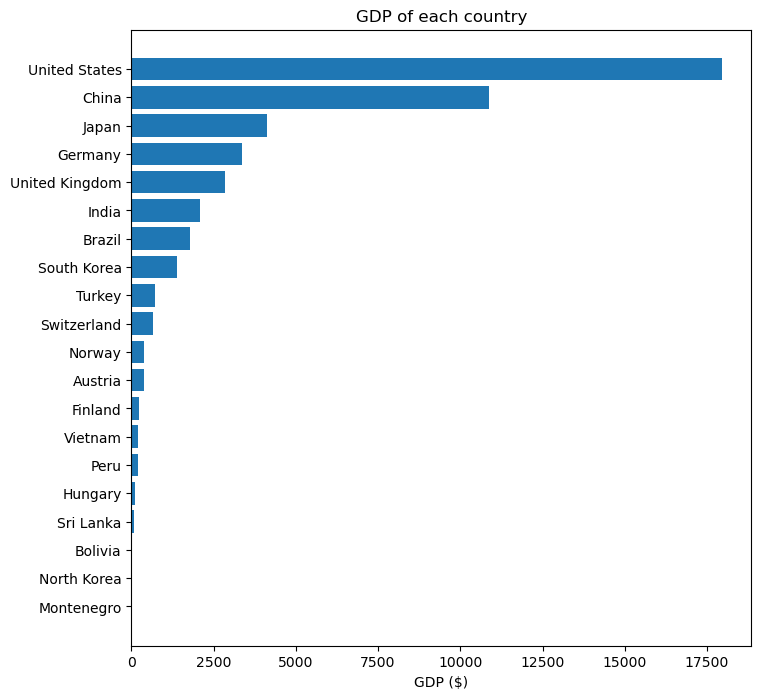

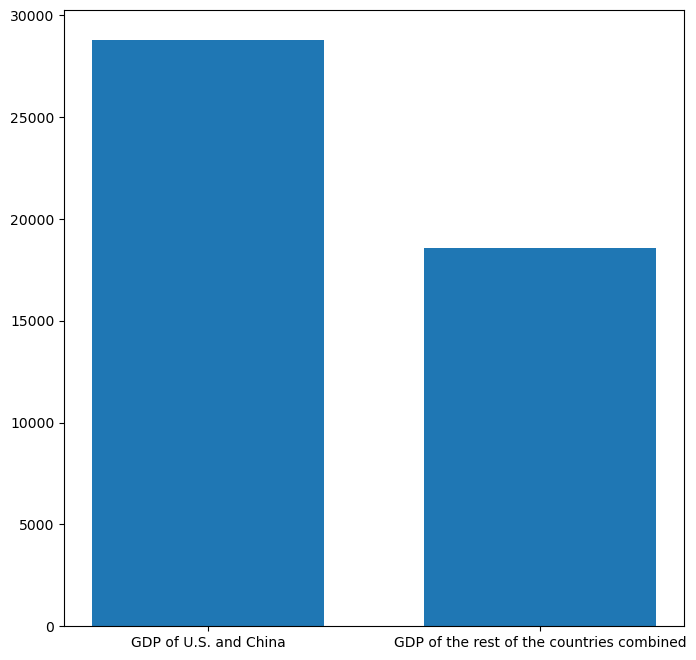

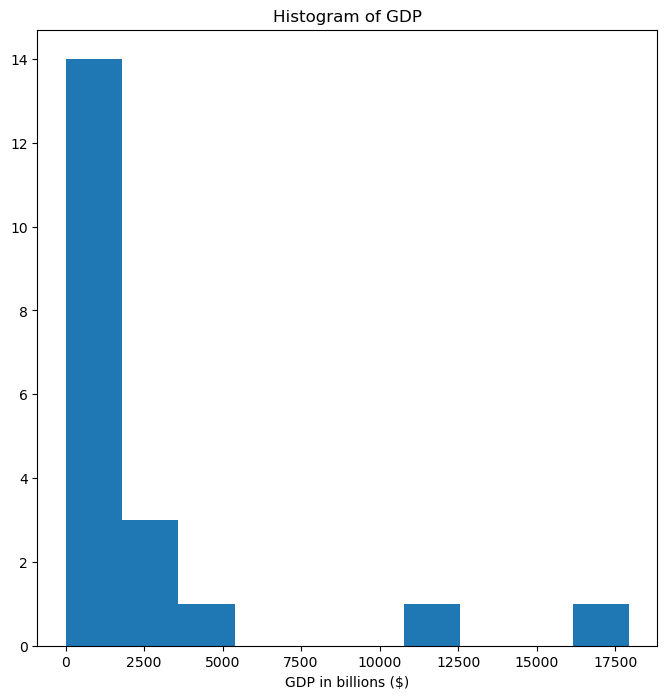

In [17]:
plt.barh(positions, np.sort(gdp))
plt.yticks(positions, countries[np.argsort(gdp)])
plt.xlabel("GDP ($)")
plt.title("GDP of each country")
plt.show()

plt.bar(np.array([0,1]), [np.sort(gdp)[-1] + np.sort(gdp)[-2], sum(np.sort(gdp)[:-2])], 0.7)
plt.xticks(np.array([0,1]), ["GDP of U.S. and China", "GDP of the rest of the countries combined"])
plt.show()

plt.hist(gdp)
plt.xlabel("GDP in billions ($)")
plt.title("Histogram of GDP")
plt.show()

**Finding:**

United States has by far the largest GDP, beating out the second largest (China) by almost 2 times. 

The combined GDP of United States and China is greater than the GDP of the rest of the 18 countries combined. 

Majority of the countries had GDP of below $2500 billion

### Population

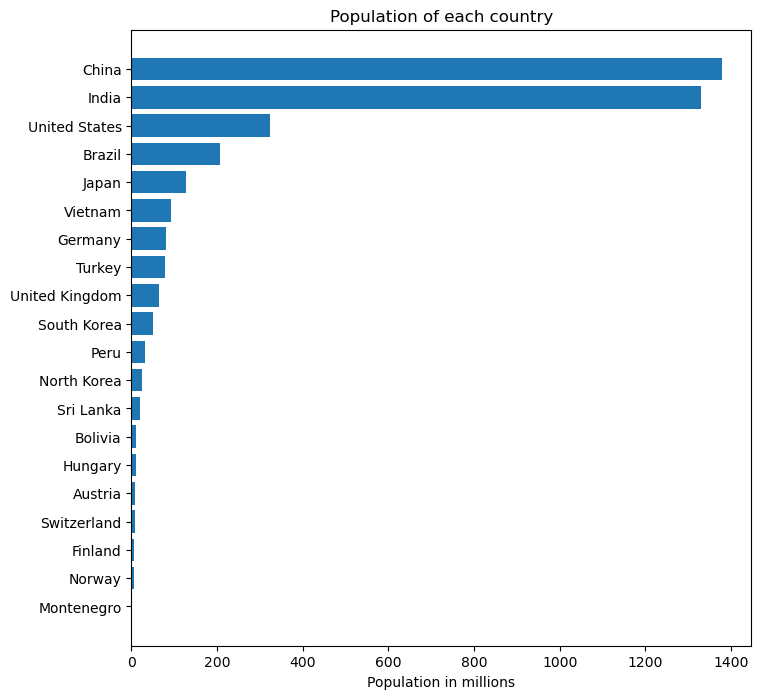

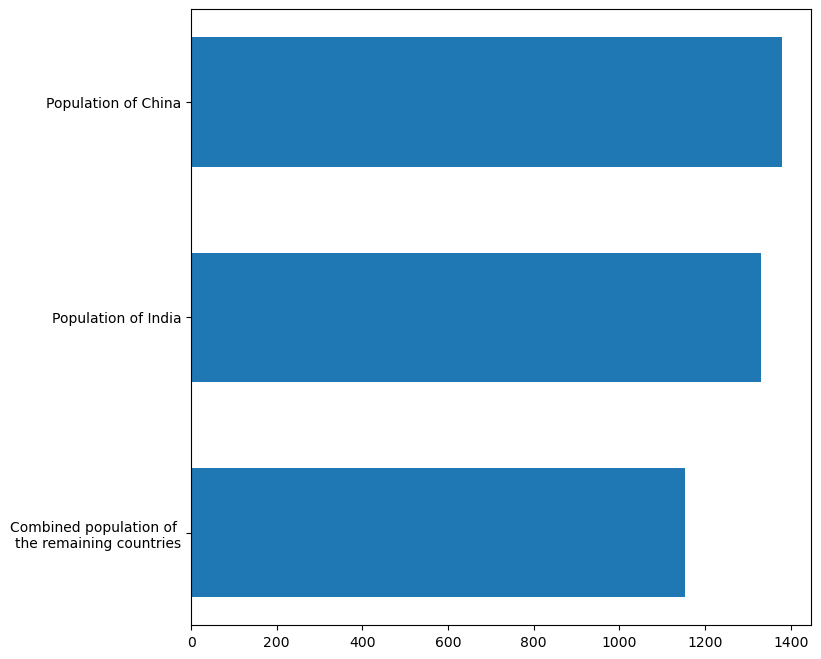

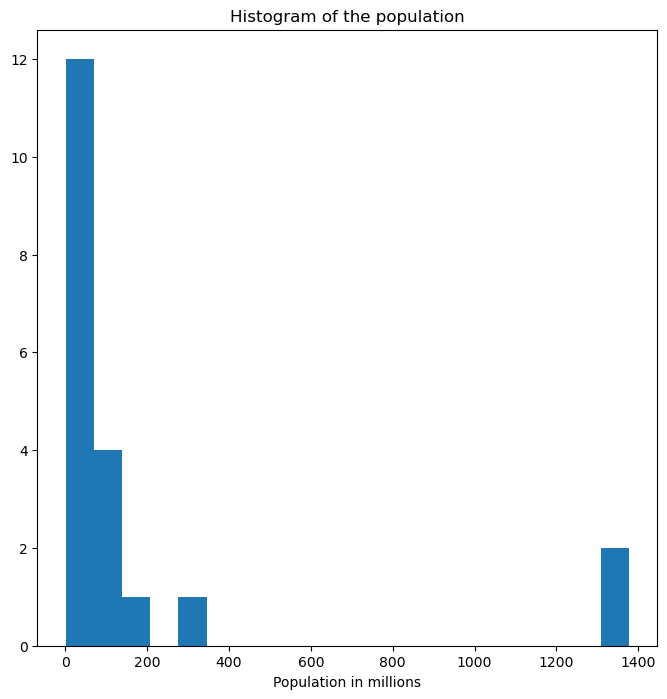

In [18]:
plt.barh(positions, np.sort(population))
plt.yticks(positions, countries[np.argsort(population)])
plt.xlabel("Population in millions")
plt.title("Population of each country")
plt.show()

plt.barh(np.array([0,1,2]), [np.sort(population)[-1], np.sort(population)[-2], sum(np.sort(population)[:-2])][::-1], 0.6)
plt.yticks(np.array([0,1,2]), ["Population of China", "Population of India", "Combined population of \nthe remaining countries"][::-1])
plt.show()

plt.hist(population, bins=20)
plt.xlabel("Population in millions")
plt.title("Histogram of the population")
plt.show()

**Findings:**

China and India has by far the highest population, and between the two, the difference is very small, while the 3rd highest (United States) has a significantly lower population.

The combined population of the other 18 countries is smaller than the individual populations of China and India

Majority of the countries has below 100 million people.

## Further Reading

The lab recommends, as written:
- *How to Lie with Statistics* by Darrell Huff (1954)
- *The Visual Display of Quantitative Information* by Edward Tufte (2nd edition)
- *Visual Explanations* by Edward Tufte
- *Envisioning Information* by Edward Tufte
- *Beautiful Evidence* by Edward Tufte
- *The Functional Art* by Alberto Cairo
- *Visualization Analysis and Design* by Tamara Munzner
- Designing New Default Colormaps: https://bids.github.io/colormap/